In [1]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Prophet. Часть 2: компоненты и их ручки

В части 1 мы разобрали, что Prophet — регрессия: шарнирный тренд + матрица признаков $X$ (Фурье-сезонности, праздники, регрессоры) с L1-приором на изломы и L2-приором на $\beta$. Теперь пройдём по каждой компоненте и посмотрим, **какой ручкой она управляется и что эта ручка меняет внутри модели**.

| Компонента | Ручки | Что меняется в модели |
|---|---|---|
| Тренд | `changepoint_prior_scale`, `changepoint_range`, `changepoints` | сила L1, сетка кандидатов $s_j$ |
| Насыщение | `growth='logistic'`, `cap`, `floor`, `growth='flat'` | вид функции $g(t)$ |
| Сезонности | `fourier_order`, `add_seasonality`, `condition_name`, `prior_scale` | столбцы $X$ и их L2-приоры |
| Мультипликативность | `seasonality_mode`, `mode=` у компоненты | столбец идёт в `X_sa` или `X_sm` |
| Праздники | `holidays`, окна, `add_country_holidays`, `holidays_prior_scale` | индикаторные столбцы $X$ и их приоры |



In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot, plot_forecast_component, plot_seasonality, plot_weekly, plot_yearly

logging.getLogger("cmdstanpy").disabled = True
plt.rcParams["figure.figsize"] = (12, 4)

Основной ряд — снова логарифм просмотров страницы Пейтона Мэннинга; прогнозируем на год вперёд.

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/data/example_wp_log_peyton_manning.csv", parse_dates=["ds"])
future = pd.DataFrame({"ds": pd.date_range(df["ds"].min(), df["ds"].max() + pd.Timedelta(days=365))})

## 1. Тренд и изломы

Напоминание: тренд $g(t) = m + k t + \sum_j \delta_j \max(0, t - s_j)$, кандидаты $s_j$ — 25 точек на первых 80 % истории, $\delta_j \sim \text{Laplace}(0, \tau)$, $\tau$ = `changepoint_prior_scale`.

### 1.1. `changepoint_prior_scale` — гибкость тренда

Маленький $\tau$ — сильный L1-штраф, почти прямая; большой $\tau$ — тренд начинает «объяснять» сезонность и шум.

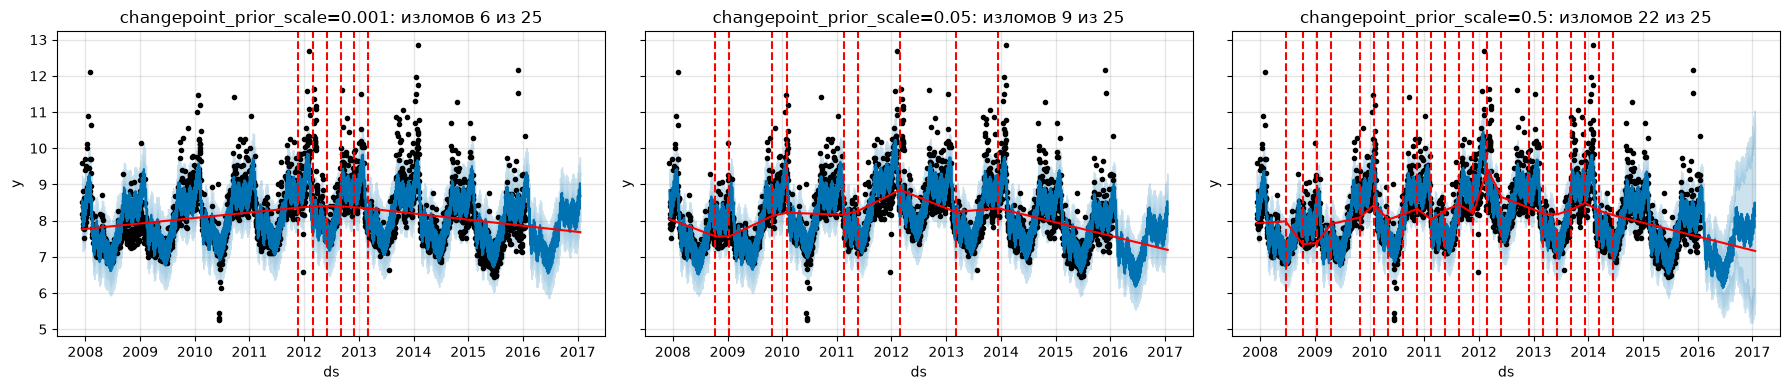

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, scale in zip(axes, [0.001, 0.05, 0.5]):
    m = Prophet(changepoint_prior_scale=scale).fit(df)
    forecast = m.predict(future)
    m.plot(forecast, ax=ax)
    add_changepoints_to_plot(ax, m, forecast)
    n_active = (np.abs(m.params["delta"]) > 0.01).sum()
    ax.set_title(f"changepoint_prior_scale={scale}: изломов {n_active} из 25")
plt.tight_layout()

- При 0.001 тренд недообучен: изменения уровня уходят в шум.
- При 0.5 тренд переобучен, и это видно по интервалу: модель ожидает в будущем такие же частые и сильные изломы (часть 1, раздел 4).

### 1.2. `changepoint_range` — где разрешены изломы

По умолчанию последние 20 % истории изломов не содержат: в конце ряда мало данных, чтобы отличить излом от шума. Если поведение ряда изменилось недавно, долю можно увеличить — тогда тренд сможет повернуть и в самом конце, но начнёт сильнее реагировать на последние точки.

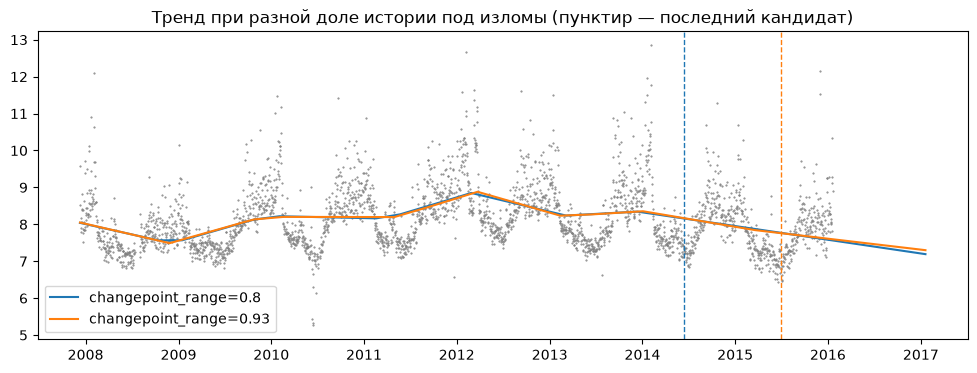

In [36]:
fig, ax = plt.subplots()
ax.plot(df["ds"], df["y"], ".", ms=1, color="grey")
for changepoint_range in [0.8, 0.93]:
    m = Prophet(changepoint_range=changepoint_range).fit(df)
    forecast = m.predict(future)
    ax.plot(forecast["ds"], forecast["trend"], label=f"changepoint_range={changepoint_range}")
    ax.axvline(m.changepoints.max(), ls="--", color=ax.lines[-1].get_color(), lw=1)
ax.set_title("Тренд при разной доле истории под изломы (пунктир — последний кандидат)")
ax.legend();

На этом ряду разница небольшая: в последние годы тренд и так плавный. Документация советует этот параметр по кросс-валидации не тюнить — по прошлым отсечкам трудно понять, как модель справится с изломом у самого края ряда.

### 1.3. Ручные изломы `changepoints`

Если дата смены режима известна (запуск продукта, смена методики), кандидатов можно задать явно. Ниже — один излом в начале 2014 года, как в документации: L1-приор продолжает действовать, но сетка кандидатов теперь из одной точки.

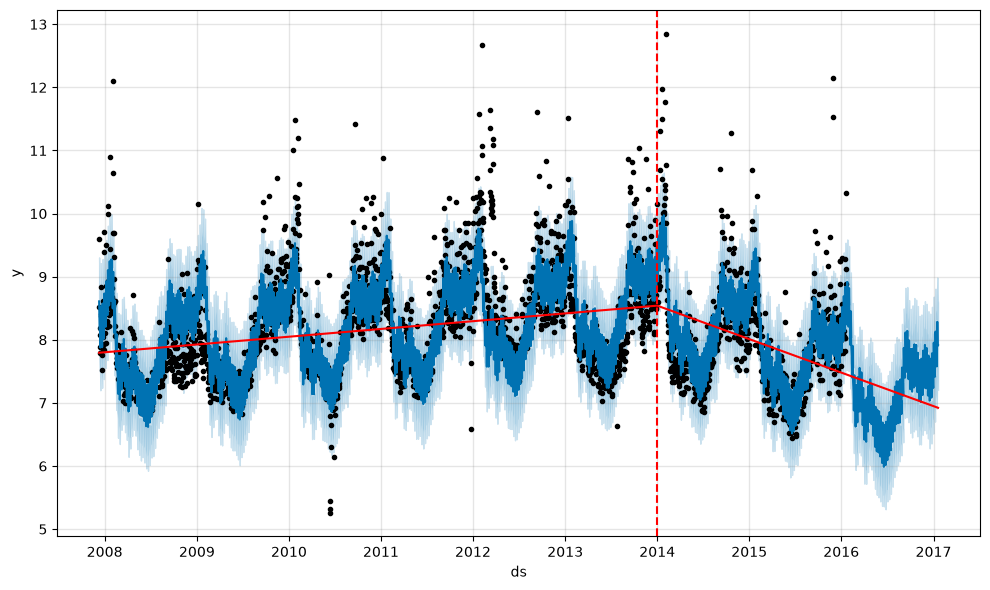

In [12]:
m = Prophet(changepoints=["2014-01-01"]).fit(df)
forecast = m.predict(future)
fig = m.plot(forecast)
add_changepoints_to_plot(fig.gca(), m, forecast);

## 2. Насыщение и постоянный тренд

### 2.1. Логистический рост: `growth='logistic'`

Когда у роста есть естественный потолок (размер рынка, население), линейный тренд в долгую неверен. Логистический тренд:
$$g(t) = \frac{C(t)}{1 + \exp\big(-(k + a(t)^\top\delta)\,(t - (m + a(t)^\top\gamma))\big)},$$
где $C(t)$ — **ёмкость** (`cap`). Её не оценивают, а **задают**: из данных или экспертно; столбец `cap` нужен и в истории, и в `future`. Изломы работают так же — меняют скорость роста.

Пример из документации — просмотры страницы Википедии о языке R, ёмкость 8.5 (в логарифмах), прогноз на 5 лет.

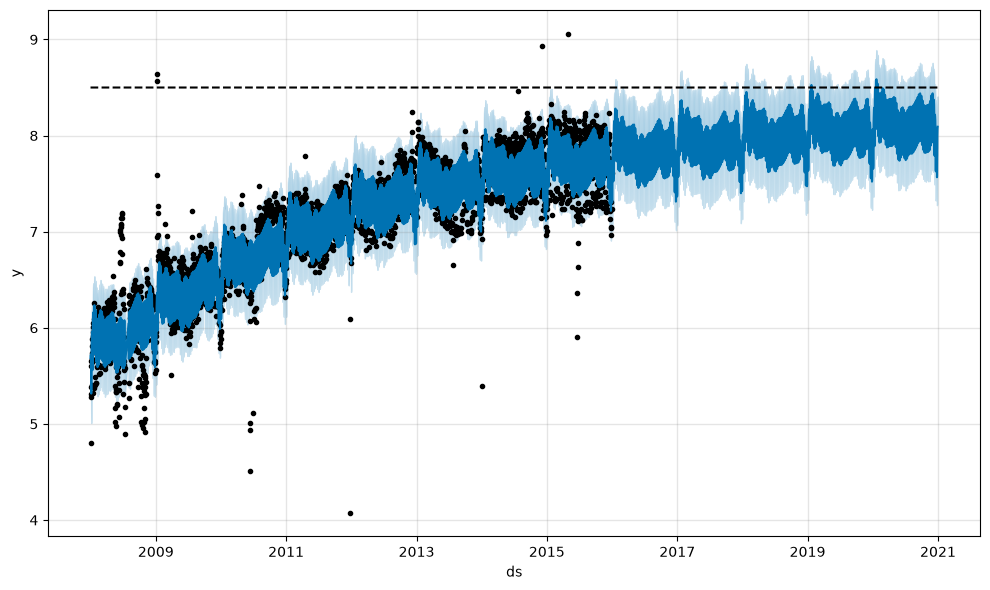

In [13]:
df_r = pd.read_csv("https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/data/example_wp_log_R.csv", parse_dates=["ds"])
df_r["cap"] = 8.5

m = Prophet(growth="logistic").fit(df_r)
future_r = m.make_future_dataframe(periods=1826)
future_r["cap"] = 8.5
fig = m.plot(m.predict(future_r))

Ёмкость не обязана быть постоянной: если рынок растёт, `cap` может расти. Сравним постоянную ёмкость с ёмкостью, которая в будущем линейно растёт до 9.5:

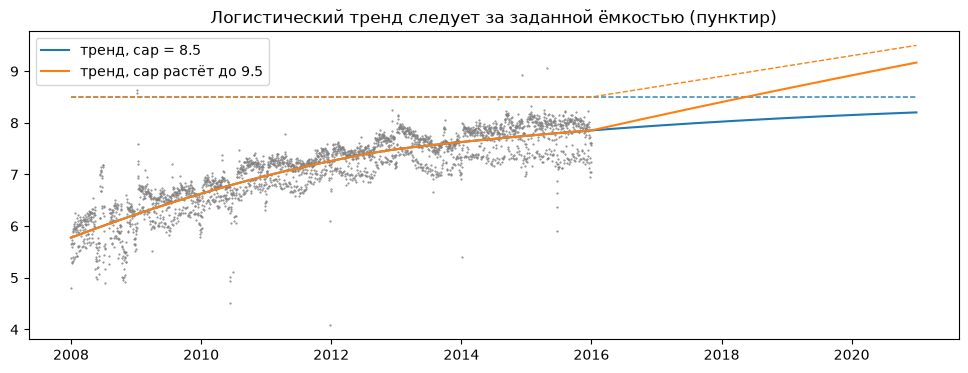

In [14]:
future_growing = future_r.copy()
in_future = future_growing["ds"] > df_r["ds"].max()
future_growing.loc[in_future, "cap"] = np.linspace(8.5, 9.5, in_future.sum())

fig, ax = plt.subplots()
ax.plot(df_r["ds"], df_r["y"], ".", ms=1, color="grey")
for name, fut in [("cap = 8.5", future_r), ("cap растёт до 9.5", future_growing)]:
    forecast = m.predict(fut)
    line, = ax.plot(forecast["ds"], forecast["trend"], label=f"тренд, {name}")
    ax.plot(fut["ds"], fut["cap"], "--", color=line.get_color(), lw=1)
ax.set_title("Логистический тренд следует за заданной ёмкостью (пунктир)")
ax.legend();

Модель уже обучена; меняя `cap` в `future`, мы меняем только сценарий будущего — это удобный инструмент «что если».

Логистическая кривая насыщается и снизу — по умолчанию на 0. Другой нижний уровень задаётся столбцом `floor` (`cap` при этом обязателен). Пример из документации: перевёрнутый ряд $10 - y$, падающий к уровню 1.5.

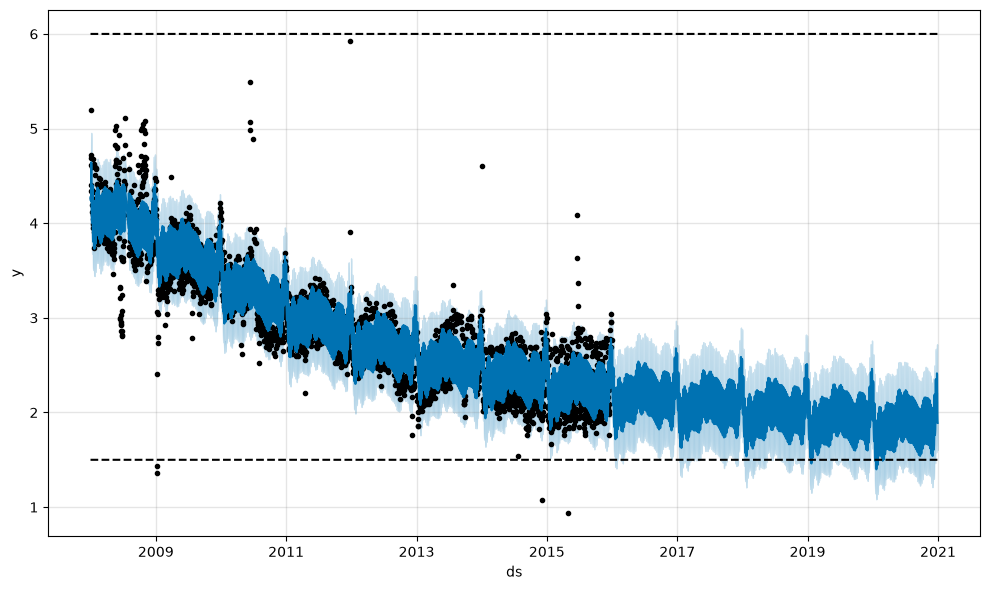

In [15]:
df_down = df_r.assign(y=10 - df_r["y"], cap=6, floor=1.5)
future_down = future_r.assign(cap=6, floor=1.5)

m = Prophet(growth="logistic").fit(df_down)
fig = m.plot(m.predict(future_down))

### 2.2. Постоянный тренд: `growth='flat'`

$g(t) = m$ — тренда нет вообще. Полезно, когда уровень ряда объясняется внешним регрессором (или его нет и ряд стационарен вокруг сезонности). Пример из *Additional topics*: почасовой поток пешеходов на датчике `location_41` объясняется соседним датчиком `location_4` (регрессор, подробно — в части 3). Учим на двух неделях, проверяем на следующих.

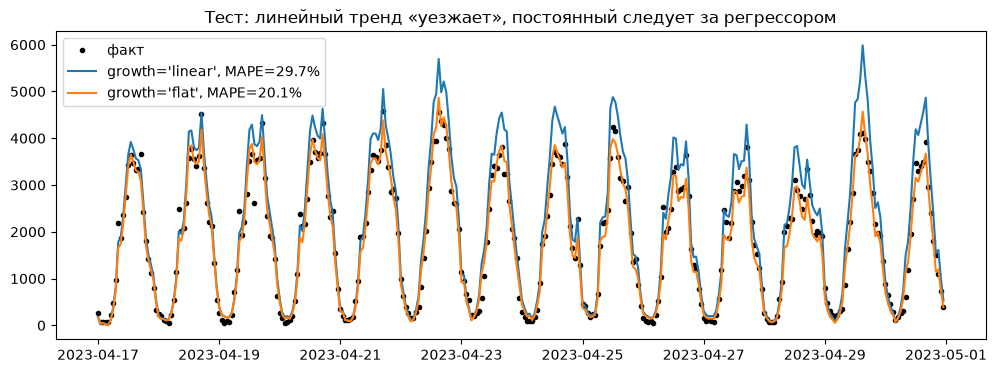

In [16]:
df_ped = pd.read_csv("https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/data/example_pedestrians_multivariate.csv", parse_dates=["ds"]).rename(columns={"location_41": "y"})
cutoff = pd.Timestamp("2023-04-17")
train, test = df_ped[df_ped["ds"] < cutoff], df_ped[df_ped["ds"] >= cutoff]

fig, ax = plt.subplots()
ax.plot(test["ds"], test["y"], ".", color="black", label="факт")
for growth in ["linear", "flat"]:
    m = Prophet(growth=growth, seasonality_mode="multiplicative", daily_seasonality=15)
    m.add_regressor("location_4", mode="multiplicative")
    forecast = m.fit(train).predict(test)
    mape = np.mean(np.abs(forecast["yhat"].to_numpy() - test["y"].to_numpy()) / test["y"].to_numpy())
    ax.plot(forecast["ds"], forecast["yhat"], label=f"growth='{growth}', MAPE={mape:.1%}")
ax.set_title("Тест: линейный тренд «уезжает», постоянный следует за регрессором")
ax.legend();

Линейный тренд, оценённый на двух неделях, экстраполирует случайный наклон — прогноз систематически завышен. Если тренда по смыслу нет, его лучше выключить.

## 3. Сезонности

### 3.1. `fourier_order` — гибкость формы

`fourier_order=N` — это $2N$ столбцов в $X$. Больше гармоник — сезонная кривая может меняться быстрее, но и переобучаться легче. Годовая сезонность Пейтона при дефолтных 10 и при 20 гармониках:

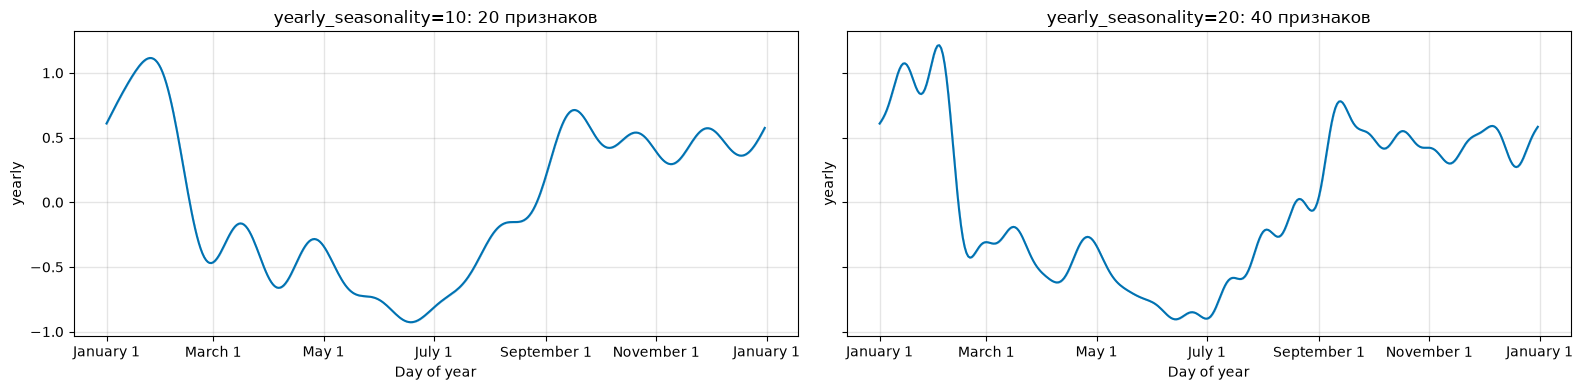

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, order in zip(axes, [10, 20]):
    m = Prophet(yearly_seasonality=order).fit(df)
    plot_yearly(m, ax=ax)
    ax.set_title(f"yearly_seasonality={order}: {2 * order} признаков")
plt.tight_layout()

При 20 гармониках кривая ловит более резкие всплески (начало сезона NFL, плей-офф), но и больше «рябит».

### 3.2. Своя сезонность: `add_seasonality`

Любой период в днях: месяц, квартал, час. Заменим недельную сезонность месячной (`period=30.5`, 5 гармоник):

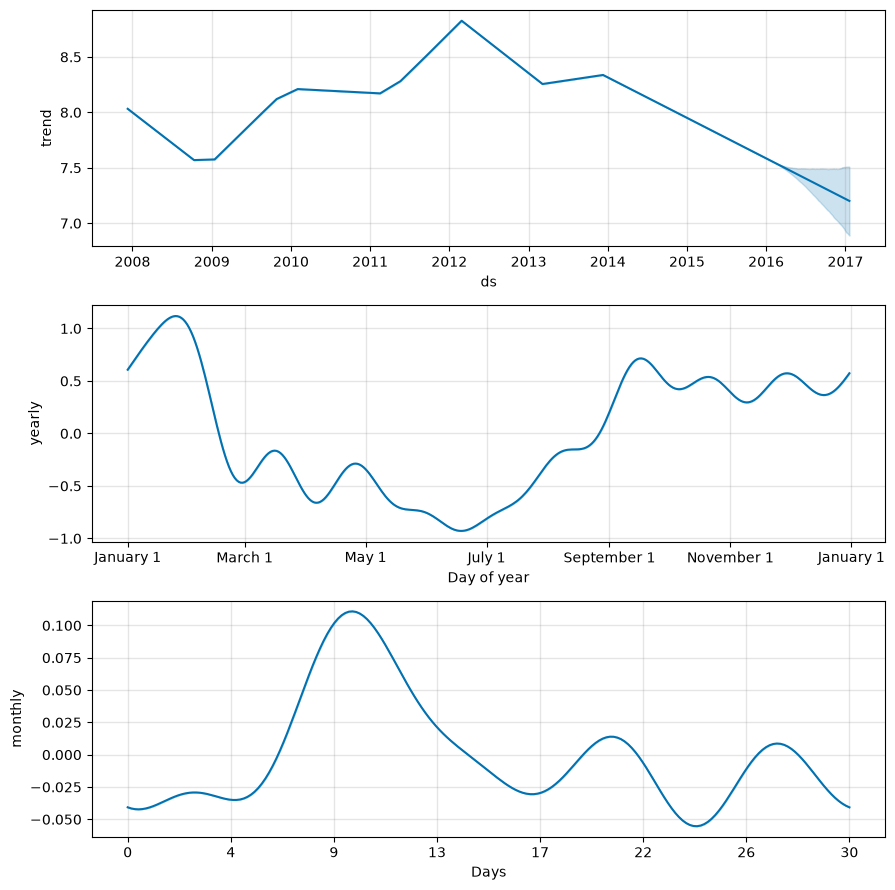

In [18]:
m = Prophet(weekly_seasonality=False)
m.add_seasonality(name="monthly", period=30.5, fourier_order=5)
forecast = m.fit(df).predict(future)
fig = m.plot_components(forecast)

Все сезонности модели вместе с их параметрами хранятся в `m.seasonalities`:

In [19]:
pd.DataFrame(m.seasonalities).T

,period,fourier_order,prior_scale,mode,condition_name
monthly,30.5,5,10.0,additive,None
yearly,365.25,10,10.0,additive,None


### 3.3. Условная сезонность: `condition_name`

Обычная сезонность одинакова весь год. Но в сезон NFL (сентябрь — январь) игры по воскресеньям, и недельный профиль просмотров должен отличаться от межсезонья.

`condition_name` — булев столбец: признаки сезонности **обнуляются** там, где условие ложно (`features[~condition] = 0` в `make_all_seasonality_features`). Две недельные сезонности с противоположными условиями = две независимые недельные кривые.

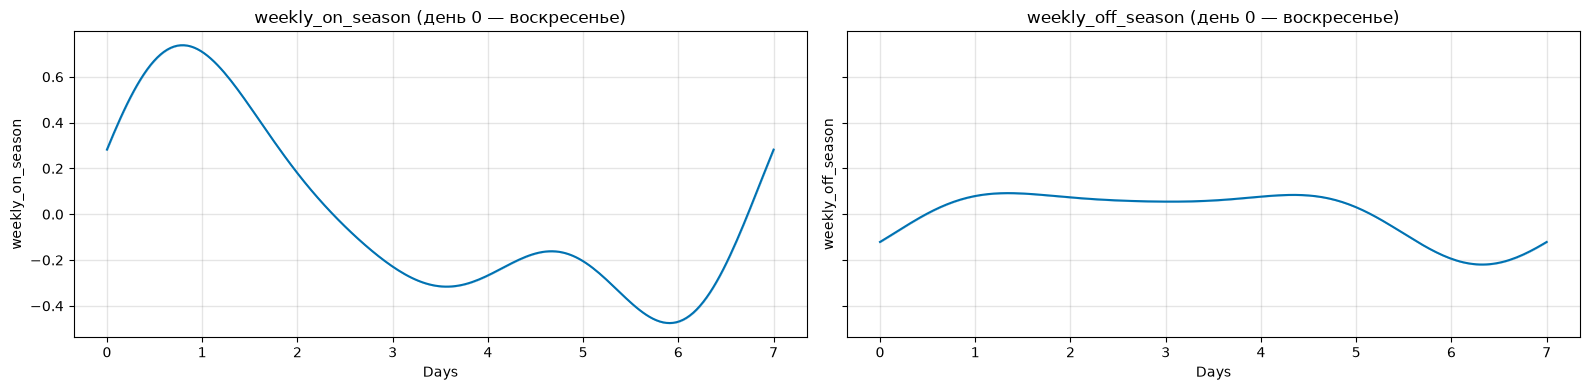

In [20]:
def is_nfl_season(ds: pd.Series) -> pd.Series:
    return (ds.dt.month > 8) | (ds.dt.month < 2)


df_season = df.assign(on_season=is_nfl_season(df["ds"]), off_season=~is_nfl_season(df["ds"]))
future_season = future.assign(on_season=is_nfl_season(future["ds"]), off_season=~is_nfl_season(future["ds"]))

m = Prophet(weekly_seasonality=False)
m.add_seasonality(name="weekly_on_season", period=7, fourier_order=3, condition_name="on_season")
m.add_seasonality(name="weekly_off_season", period=7, fourier_order=3, condition_name="off_season")
m.fit(df_season)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, ["weekly_on_season", "weekly_off_season"]):
    plot_seasonality(m, name, ax=ax)
    ax.set_title(f"{name} (день 0 — воскресенье)")
plt.tight_layout()

В сезон — большие всплески в воскресенье и понедельник (день игры и обсуждение), в межсезонье их нет вообще.

### 3.4. `seasonality_prior_scale` — сила сезонности

Каждому столбцу $X$ соответствует свой масштаб нормального приора $\sigma_i$ (L2-штраф $\beta_i^2 / 2\sigma_i^2$). `seasonality_prior_scale` задаёт его для всех сезонностей сразу, `prior_scale` в `add_seasonality` — для одной. Дефолт 10 почти не штрафует; уменьшаем — амплитуда сжимается к нулю.

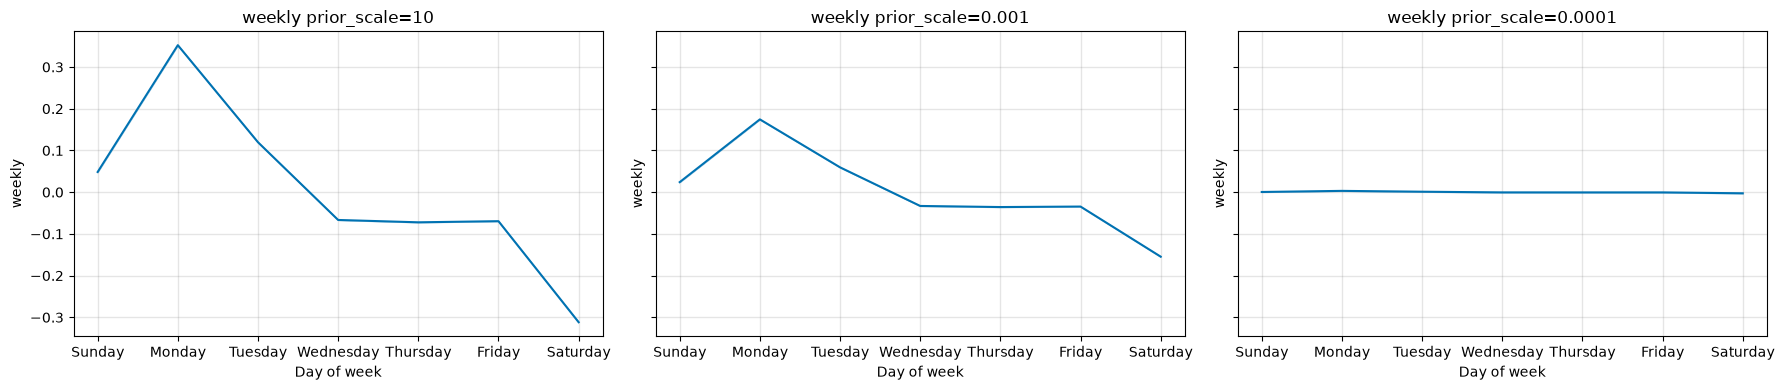

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, prior_scale in zip(axes, [10, 0.001, 0.0001]):
    m = Prophet(weekly_seasonality=False)
    m.add_seasonality(name="weekly", period=7, fourier_order=3, prior_scale=prior_scale)
    m.fit(df)
    plot_weekly(m, ax=ax)
    ax.set_title(f"weekly prior_scale={prior_scale}")
plt.tight_layout()

Эффект заметен только при очень маленьких значениях. Причина — масштаб: $\beta$ живут на нормированном $y / \max|y|$, амплитуда недельной сезонности Пейтона ≈ 0.35 / 12.8 ≈ 0.03, то есть сами коэффициенты порядка 0.01. Приор начинает сжимать, когда $\sigma_i$ сравним с ними или меньше; к тому же у длинного ряда (2905 точек) правдоподобие перевешивает приор.

Документация отмечает, что сезонность переобучается редко: усечённый ряд Фурье сам по себе — фильтр низких частот. Поэтому сначала стоит подбирать `fourier_order`, а `seasonality_prior_scale` тюнить по кросс-валидации (часть 4).

## 4. Мультипликативная сезонность

В аддитивной модели амплитуда сезонности постоянна. У многих бизнес-рядов она растёт вместе с уровнем — классика: число авиапассажиров по месяцам.

$$\text{additive: } y = g(t) + s(t), \qquad \text{multiplicative: } y = g(t)\,(1 + s(t)).$$

В Stan-модели это просто другая матрица: столбец идёт не в `X_sa` (прибавляется), а в `X_sm` (умножает тренд).

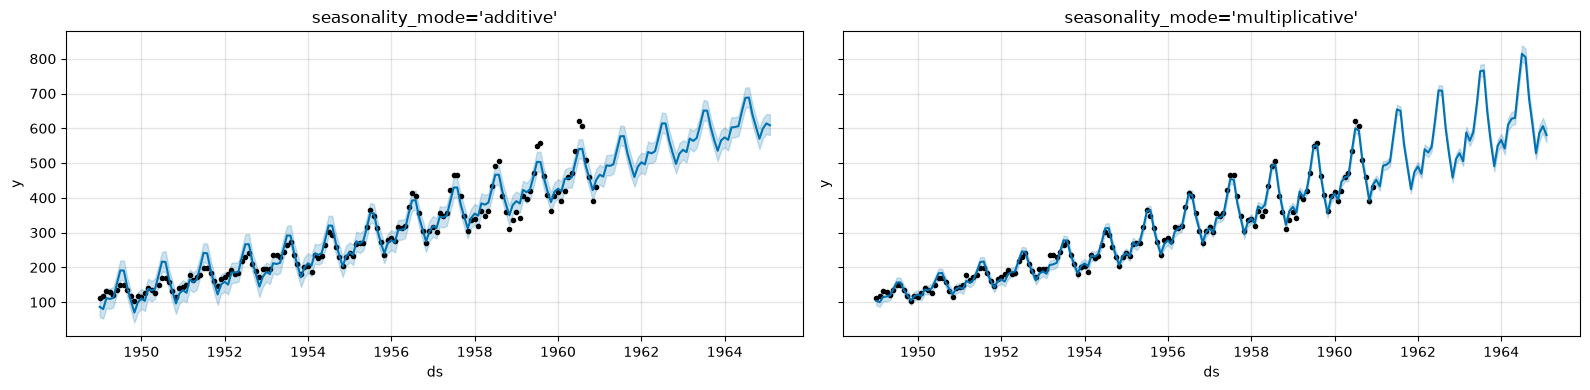

In [22]:
df_air = pd.read_csv("https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/data/example_air_passengers.csv", parse_dates=["ds"])

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, mode in zip(axes, ["additive", "multiplicative"]):
    m = Prophet(seasonality_mode=mode).fit(df_air)
    future_air = m.make_future_dataframe(periods=50, freq="MS")
    forecast_air = m.predict(future_air)
    m.plot(forecast_air, ax=ax)
    ax.set_title(f"seasonality_mode='{mode}'")
plt.tight_layout()

Аддитивная модель занижает размах в конце ряда и завышает в начале. В мультипликативной сезонность и праздники измеряются **в долях тренда**:

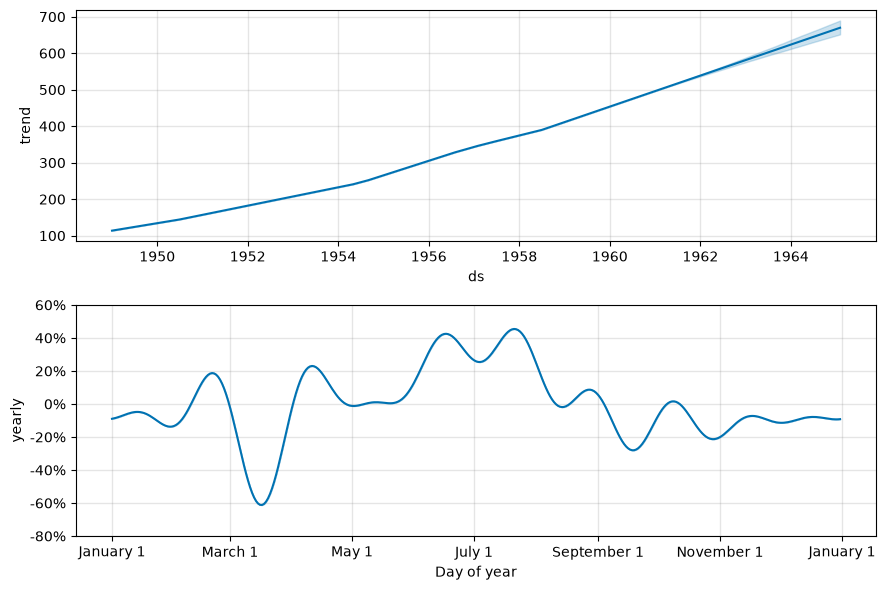

In [23]:
fig = m.plot_components(forecast_air)

Режим задаётся и для отдельной компоненты — смешанная модель:
```python
m = Prophet(seasonality_mode="multiplicative")
m.add_seasonality("quarterly", period=91.25, fourier_order=8, mode="additive")
m.add_regressor("regressor", mode="additive")
```
Какие компоненты в каком режиме, видно в `m.component_modes`:

In [24]:
m.component_modes

{'additive': ['additive_terms', 'extra_regressors_additive'],
 'multiplicative': ['yearly',
  'multiplicative_terms',
  'extra_regressors_multiplicative',
  'holidays']}

**Альтернатива — логарифм.** $\log y = \log g + \log(1 + s)$: мультипликативная модель становится аддитивной. Именно поэтому ряды из документации (Пейтон, R) уже прологарифмированы. Аддитивный Prophet на $\log y$ с возвратом через $\exp$ даёт похожий прогноз (но тренд в логарифмах — экспоненциальный рост в исходной шкале):

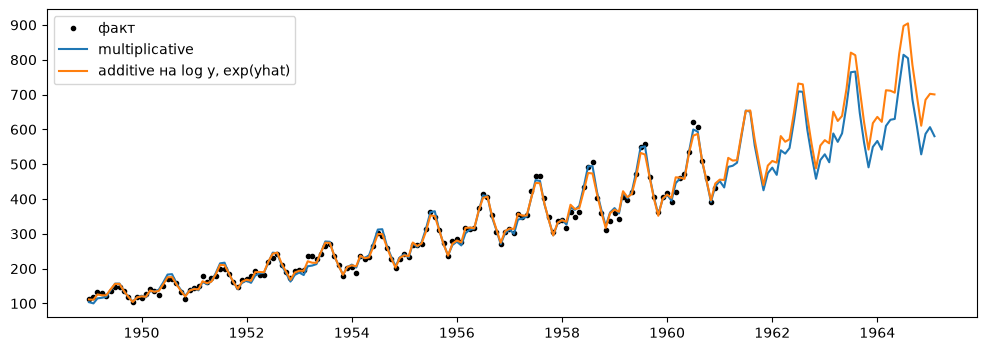

In [25]:
m_log = Prophet().fit(df_air.assign(y=np.log(df_air["y"])))
forecast_log = m_log.predict(future_air)

fig, ax = plt.subplots()
ax.plot(df_air["ds"], df_air["y"], "k.", label="факт")
ax.plot(forecast_air["ds"], forecast_air["yhat"], label="multiplicative")
ax.plot(forecast_log["ds"], np.exp(forecast_log["yhat"]), label="additive на log y, exp(yhat)")
ax.legend();

## 5. Праздники и события

### 5.1. Свой календарь событий

Таблица событий: столбцы `holiday` (имя) и `ds` (дата), по строке на каждое наступление — **и в истории, и в будущем** (событие без будущих дат модель оценит, но в прогноз не перенесёт). Окно `[lower_window, upper_window]` расширяет событие на соседние дни.

Внутри модели каждый день окна — отдельный индикаторный столбец $X$ со своим $\beta$. Для Пейтона: все игры плей-офф и отдельно Супербоулы, плюс следующий день.

In [26]:
playoffs = pd.DataFrame({
    "holiday": "playoff",
    "ds": pd.to_datetime([
        "2008-01-13", "2009-01-03", "2010-01-16", "2010-01-24", "2010-02-07", "2011-01-08", "2013-01-12",
        "2014-01-12", "2014-01-19", "2014-02-02", "2015-01-11", "2016-01-17", "2016-01-24", "2016-02-07",
    ]),
    "lower_window": 0,
    "upper_window": 1,
})
superbowls = pd.DataFrame({
    "holiday": "superbowl",
    "ds": pd.to_datetime(["2010-02-07", "2014-02-02", "2016-02-07"]),
    "lower_window": 0,
    "upper_window": 1,
})
holidays = pd.concat([playoffs, superbowls])

m = Prophet(holidays=holidays).fit(df)
forecast = m.predict(future)

features = m.make_all_seasonality_features(m.history)[0]
features.columns[features.columns.str.startswith(("playoff", "superbowl"))].tolist()

['playoff_delim_+0',
 'playoff_delim_+1',
 'superbowl_delim_+0',
 'superbowl_delim_+1']

Супербоулы входят и в `playoff`, поэтому эффект `superbowl` — **добавка** сверху к эффекту плей-офф. Эффекты событий в прогнозе:

In [27]:
event_days = (forecast["playoff"] + forecast["superbowl"]).abs() > 0
forecast.loc[event_days, ["ds", "playoff", "superbowl"]].tail(10)

,ds,playoff,superbowl
2246,2014-02-02,1.227805,1.203711
2247,2014-02-03,1.900025,1.453160
2589,2015-01-11,1.227805,0.000000
2590,2015-01-12,1.900025,0.000000
2960,2016-01-17,1.227805,0.000000
2961,2016-01-18,1.900025,0.000000
2967,2016-01-24,1.227805,0.000000
2968,2016-01-25,1.900025,0.000000
2981,2016-02-07,1.227805,1.203711
2982,2016-02-08,1.900025,1.453160


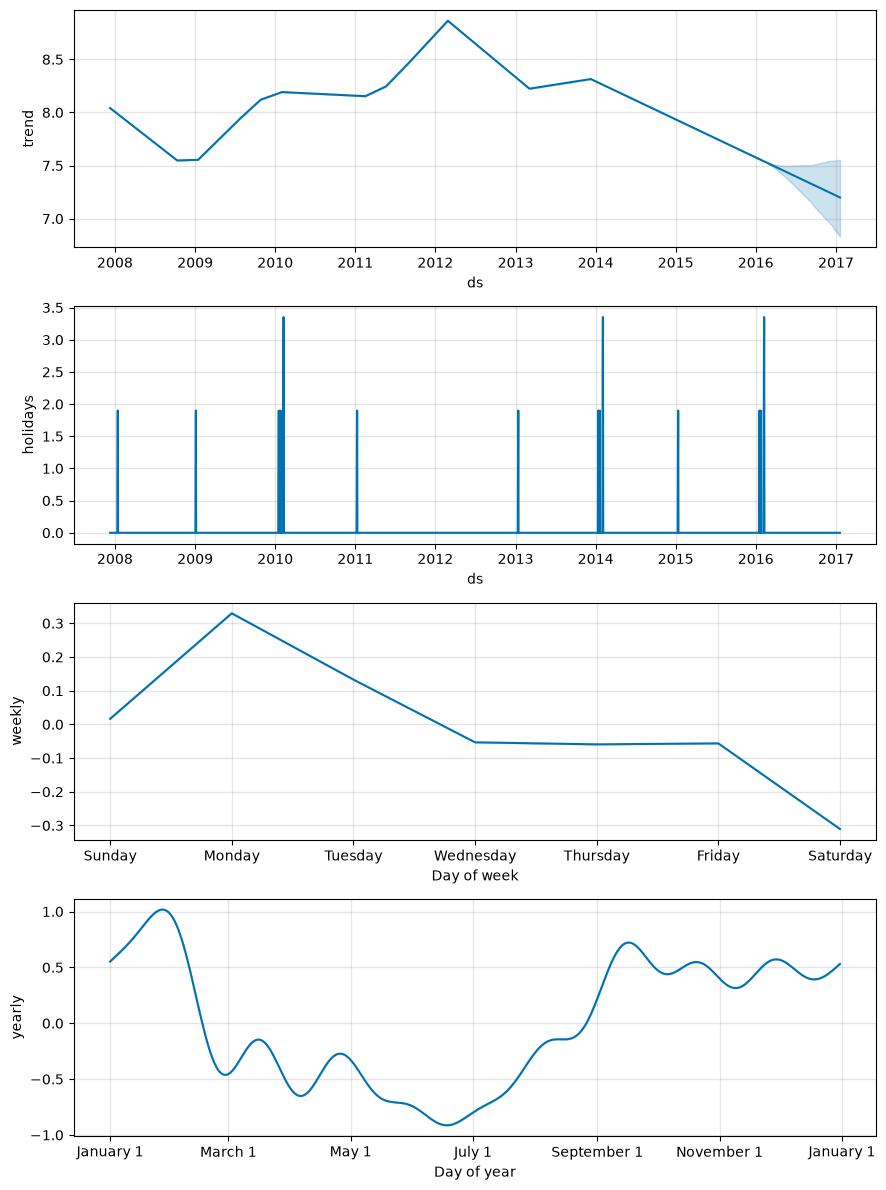

In [28]:
fig = m.plot_components(forecast)

Отдельную компоненту можно нарисовать через `plot_forecast_component`:

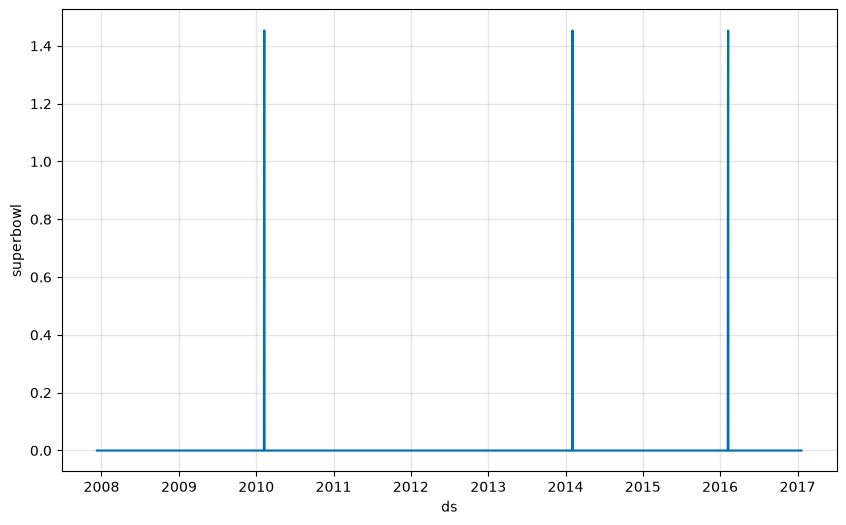

In [29]:
fig = plot_forecast_component(m, forecast, "superbowl")

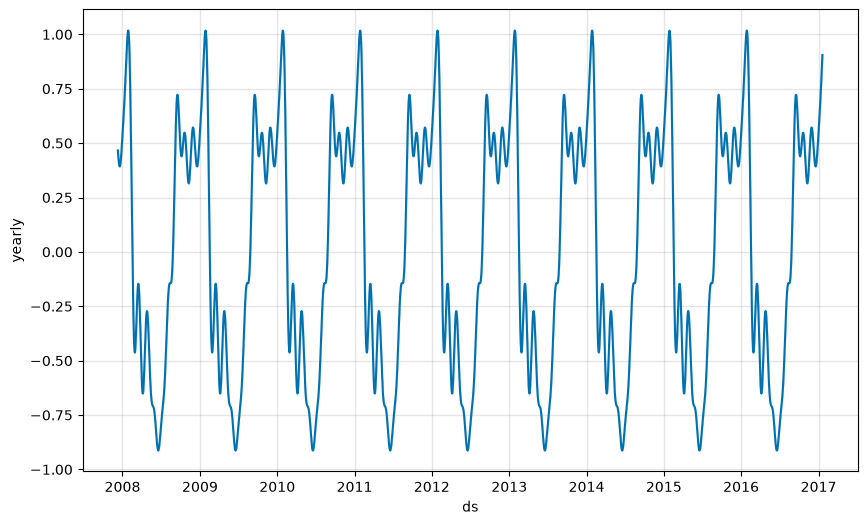

In [32]:
fig = plot_forecast_component(m, forecast, "yearly")

### 5.2. Государственные праздники: `add_country_holidays`

Встроенные календари из пакета `holidays` добавляются одной строкой, вместе со своими событиями:

In [33]:
m = Prophet(holidays=holidays)
m.add_country_holidays(country_name="US")
m.fit(df)
m.train_holiday_names

0                         playoff
1                       superbowl
2                  New Year's Day
3                    Memorial Day
4                Independence Day
5                       Labor Day
6                Thanksgiving Day
7                   Christmas Day
8        Christmas Day (observed)
9      Martin Luther King Jr. Day
10          Washington's Birthday
11                   Columbus Day
12                   Veterans Day
13        Veterans Day (observed)
14    Independence Day (observed)
15      New Year's Day (observed)
dtype: object

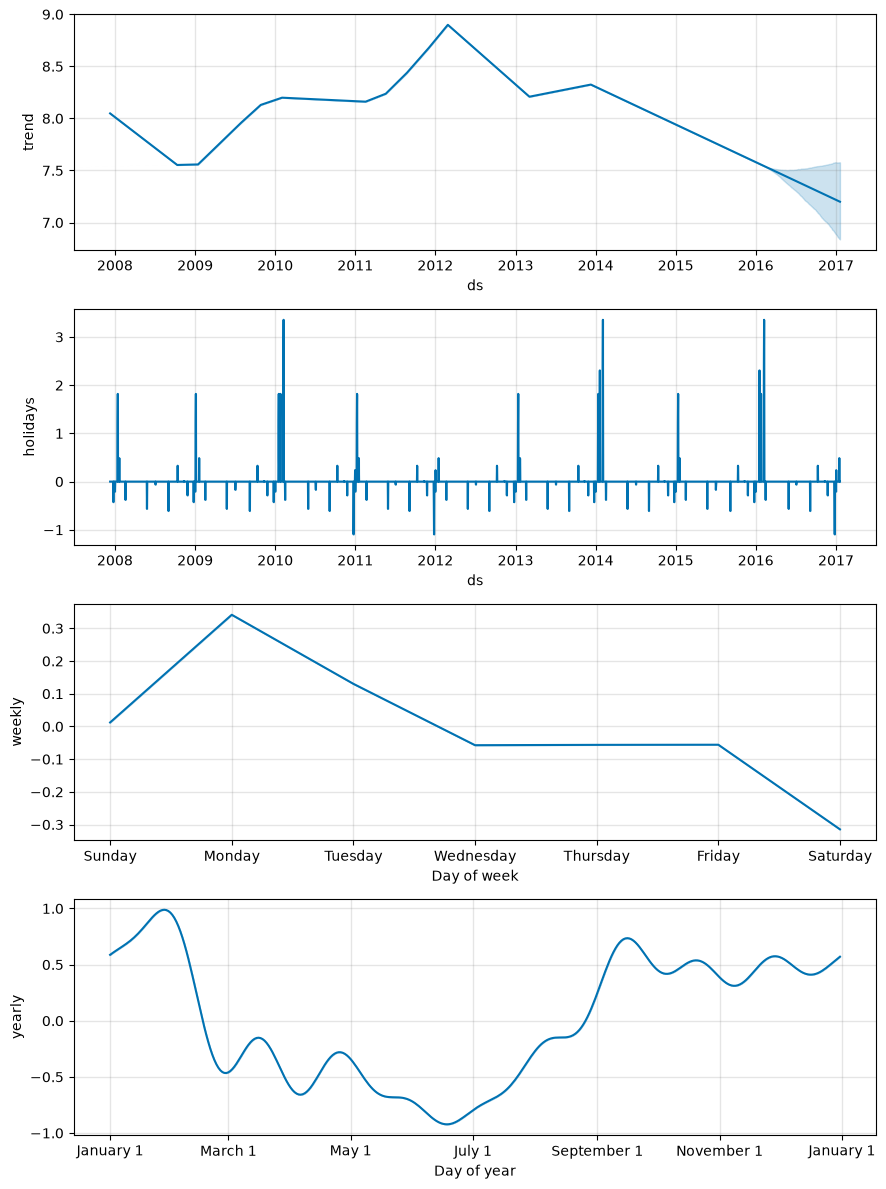

In [34]:
fig = m.plot_components(m.predict(future))

Для регионов (штатов, провинций) есть `prophet.make_holidays.make_holidays_df(year_list, country, province)` — возвращает такую же таблицу для аргумента `holidays`.

### 5.3. `holidays_prior_scale` — сила праздничных эффектов

Аналог `seasonality_prior_scale` для столбцов-праздников (дефолт 10). Уменьшение сжимает эффекты, сильнее всего — у редких событий: Супербоулов в истории всего 3, у них меньше данных против приора.

In [35]:
effects = {}
for prior_scale in [10, 0.05]:
    forecast = Prophet(holidays=holidays, holidays_prior_scale=prior_scale).fit(df).predict(future)
    effects[prior_scale] = forecast.loc[event_days, ["playoff", "superbowl"]].abs().max()
pd.DataFrame(effects).rename(columns=lambda scale: f"holidays_prior_scale={scale}").round(3)

,holidays_prior_scale=10.0,holidays_prior_scale=0.05
playoff,1.900,1.849
superbowl,1.453,1.010


Для отдельного события масштаб приора задаётся столбцом `prior_scale` в таблице праздников, например `superbowls["prior_scale"] = 0.1`.

## Итоги

- **Тренд**: `changepoint_prior_scale` — главная ручка (сила L1 на изломы); `changepoint_range` и `changepoints` меняют сетку кандидатов.
- **Насыщение**: `growth='logistic'` с заданными `cap`/`floor` — ёмкость не оценивается, а задаётся сценарием; `growth='flat'` — когда тренда по смыслу нет.
- **Сезонности**: `fourier_order` — число столбцов $X$; `add_seasonality` — любой период; `condition_name` — разные профили в разных режимах; `prior_scale` — L2-штраф.
- **Мультипликативность**: столбец умножает тренд вместо прибавления; альтернатива — логарифм ряда.
- **Праздники**: индикаторы по дням окна; будущие даты обязательны; `holidays_prior_scale` сильнее всего сжимает редкие события.

Дальше (часть 3): внешние регрессоры, шоки (COVID) и данные с частотой не «раз в день».